# Инспектор конвертации Qwen -> D16Qwen и визуализация орбит $\mathbb{Z}_8 \rtimes \mathbb{Z}_2$

Этот блокнот визуализирует процесс сборки нативной модели `D16QwenForCausalLM` (`src/d16_qwen_model.py`) из весов вещественной сети Qwen с помощью конвертера `QwenToD16Converter` (`src/d16_qwen_converter.py`) и утилит `src/d16_vis_utils.py`:
1. **Обнаружение связанных четвёрок нейронов**, образующих единое комплексное число `D16Complex`.
2. **Полярный 16-секторный компас** (`[0°, 22.5°]` фундаментальный клин и секторы `S0..S15`) для отдельных четвёрок нейронов.
3. **Спектр всех 16 операций диэдральной группы $\mathbb{Z}_8 \rtimes \mathbb{Z}_2$** (осевые `0..7` $\mathrm{Im}(z^2)$ против $45^\circ$-поворотов Адамара `8..15` $\mathrm{Re}(z^2)$) по слоям сети.
4. **Полярные профили 18-секторных таблиц усиления** `sector_im_gain` и `sector_re_gain`.

In [1]:
%matplotlib inline
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

# Подключаем папку src проекта D:\repo\d16nn\qwen\src
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "ipynb" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from d16_complex import D16Complex, D16ComplexTensor, STATE_LABELS
from d16_qwen_model import D16QwenConfig, D16QwenForCausalLM
from d16_qwen_converter import (
    OP_NAMES,
    QwenToD16Converter,
    convert_mlp_layer_to_d16,
    d16_group_matrices,
)
from d16_vis_utils import (
    plot_layer_z8z2_spectrum,
    plot_learned_sector_gains,
    plot_single_orbit_compass,
    print_orbit_table,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
print(f"Using device: {device}")

Using device: cuda


## 1. Загрузка весов Qwen2.5-0.5B (или генерация эталонного чекпоинта с известными орбитами)
Если локальный чекпоинт `Qwen/Qwen2.5-0.5B` найден в кэше HuggingFace (или по пути `QWEN_LOCAL_PATH`), конвертируем реальные веса Qwen. Если локальный чекпоинт не указан, автоматически создаётся многослойный стенд с вшитыми орбитами $\mathbb{Z}_8 \rtimes \mathbb{Z}_2$, чтобы все графики работали автономно.

In [2]:
# Укажи путь к локальной папке с config.json и model.safetensors (или оставь None для автопоиска в HF cache)
QWEN_LOCAL_PATH = None
CONVERSION_MODE = "orbit_4to1"  # "orbit_4to1" (4 нейрона -> 1 D16Complex) или "full_1to1"

def find_local_qwen_snapshot(model_id: str = "Qwen/Qwen2.5-0.5B") -> Path | None:
    if QWEN_LOCAL_PATH and Path(QWEN_LOCAL_PATH).is_dir():
        return Path(QWEN_LOCAL_PATH)
    hf_home = Path(os.environ.get("HF_HOME", Path.home() / ".cache" / "huggingface"))
    hub_dir = hf_home / "hub" / ("models--" + model_id.replace("/", "--"))
    snaps = list((hub_dir / "snapshots").glob("*")) if (hub_dir / "snapshots").is_dir() else []
    for s in snaps:
        if (s / "config.json").is_file():
            return s
    return None


def build_synthetic_qwen_with_orbits(num_layers: int = 6, hidden_size: int = 64, inter_size: int = 128):
    """Создает стендовый state_dict Qwen с реалистичными орбитами Z_8 |>< Z_2 в каждом слое."""
    cfg = {
        "vocab_size": 256,
        "hidden_size": hidden_size,
        "intermediate_size": inter_size,
        "num_hidden_layers": num_layers,
        "num_attention_heads": 4,
        "num_key_value_heads": 2,
        "max_position_embeddings": 512,
        "rms_norm_eps": 1e-6,
        "rope_theta": 10000.0,
        "tie_word_embeddings": True,
    }
    mats = d16_group_matrices(dtype=torch.float32)
    kv_dim = (hidden_size // 4) * 2
    sd = {
        "model.embed_tokens.weight": torch.randn(256, hidden_size) * 0.02,
        "model.norm.weight": torch.ones(hidden_size),
    }
    K = inter_size // 4
    for l_idx in range(num_layers):
        p = f"model.layers.{l_idx}."
        sd[p + "input_layernorm.weight"] = torch.ones(hidden_size)
        sd[p + "post_attention_layernorm.weight"] = torch.ones(hidden_size)
        for proj, out_d in [("q_proj", hidden_size), ("k_proj", kv_dim), ("v_proj", kv_dim)]:
            sd[p + f"self_attn.{proj}.weight"] = torch.randn(out_d, hidden_size) * 0.02
            sd[p + f"self_attn.{proj}.bias"] = torch.zeros(out_d)
        sd[p + "self_attn.o_proj.weight"] = torch.randn(hidden_size, hidden_size) * 0.02

        base_B = F.normalize(torch.randn(K, 2, hidden_size), dim=-1) * 1.2
        U_rows, G_rows = [], []
        for q in range(K):
            # В средних слоях повышаем долю 45°-поворотов Адамара (op in 8..15)
            ops_q = [0, 1 + (q % 7), 8 + ((q + l_idx) % 8), 8 + ((q * 3 + l_idx) % 8)]
            for op_id in ops_q:
                noise = torch.randn(2, hidden_size) * (0.04 + 0.02 * (q / K))
                mapped = mats[op_id] @ base_B[q] + noise
                U_rows.append(mapped[0])
                G_rows.append(mapped[1])
        perm = torch.randperm(inter_size)
        sd[p + "mlp.up_proj.weight"] = torch.stack(U_rows, dim=0)[perm]
        sd[p + "mlp.gate_proj.weight"] = torch.stack(G_rows, dim=0)[perm]
        sd[p + "mlp.down_proj.weight"] = torch.randn(hidden_size, inter_size) * 0.1
    return cfg, sd


snap_dir = find_local_qwen_snapshot("Qwen/Qwen2.5-0.5B")
if snap_dir is not None:
    print(f"Загружаем реальный чекпоинт Qwen2.5-0.5B из: {snap_dir}")
    d16_model, conv_report = QwenToD16Converter.from_pretrained_dir(
        snap_dir, mode=CONVERSION_MODE, device="cpu"
    )
else:
    print("Локальный кэш Qwen2.5-0.5B не найден — используем многослойный стенд с орбитами Z_8 |>< Z_2.")
    mock_cfg, mock_sd = build_synthetic_qwen_with_orbits(num_layers=6, hidden_size=64, inter_size=128)
    d16_model, conv_report = QwenToD16Converter.convert_state_dict(
        mock_sd, mock_cfg, mode=CONVERSION_MODE, device="cpu"
    )

print(f"Конвертация завершена! Сконвертировано слоев: {conv_report.num_layers}")
print(f"Размерность MLP: {conv_report.orig_intermediate_size} вещественных -> {conv_report.d16_intermediate_size} узлов D16Complex")
print(f"Средний косинус орбиты по сети: {conv_report.mean_orbit_score:.4f}")
print(f"Средняя доля 45°-связей Адамара Re(z^2): {conv_report.mean_hadamard_45_pct:.1f}%")

Загружаем реальный чекпоинт Qwen2.5-0.5B из: C:\Users\Сергей\.cache\huggingface\hub\models--Qwen--Qwen2.5-0.5B\snapshots\060db6499f32faf8b98477b0a26969ef7d8b9987
Конвертация завершена! Сконвертировано слоев: 24
Размерность MLP: 4864 вещественных -> 1216 узлов D16Complex
Средний косинус орбиты по сети: 0.1667
Средняя доля 45°-связей Адамара Re(z^2): 46.3%


## 2. Таблица связанных нейронов, образующих одно число `D16Complex`
Выведем топ-10 самых чистых орбит выбранного слоя: для каждого узла `D16Complex` показаны 4 исходных вещественных нейрона `n=...`, операция группы $\mathbb{Z}_8 \rtimes \mathbb{Z}_2$ (`op=0..15`) и принадлежность к осевой ветви $\mathrm{Im}(z^2)$ или диагональной $45^\circ$-ветви $\mathrm{Re}(z^2)$.

In [3]:
INSPECT_LAYER = min(2, conv_report.num_layers - 1)
layer_rep = conv_report.layer_reports[INSPECT_LAYER]
print_orbit_table(layer_rep, top_k=10)

СЛОЙ  2 | Режим: orbit_4to1 | Нейронов: 4864 -> 1216 D16Complex | Средний score: 0.1541 | Доля 45° Re(z^2): 40.2%
D16 # |  Score | Якорь (m=0)    | Партнер m=1 (op)           | Партнер m=2 (op)           | Партнер m=3 (op)          
--------------------------------------------------------------------------------------------------------------------
    0 | 0.5577 | n=2325 [op= 0] | n=411  [op=15, Re 45°]     | n=4283 [op= 2, Im ax ]     | n=2885 [op= 1, Im ax ]    
    1 | 0.5118 | n=1253 [op= 0] | n=234  [op=10, Re 45°]     | n=3484 [op= 6, Im ax ]     | n=2048 [op=13, Re 45°]    
    2 | 0.5084 | n=2129 [op= 0] | n=2249 [op=10, Re 45°]     | n=487  [op= 6, Im ax ]     | n=3584 [op=12, Re 45°]    
    3 | 0.5079 | n=3429 [op= 0] | n=804  [op=10, Re 45°]     | n=4751 [op= 3, Im ax ]     | n=1535 [op=11, Re 45°]    
    4 | 0.4968 | n=989  [op= 0] | n=3214 [op=14, Re 45°]     | n=2801 [op= 4, Im ax ]     | n=4409 [op= 9, Re 45°]    
    5 | 0.4675 | n=4486 [op= 0] | n=297  [op=12, Re 45°

## 3. Круговой 16-секторный компас: как 4 вещественных нейрона раскладываются по секторам `S0..S15`
Нарисуем полярные диаграммы для двух узлов `D16Complex` (`unit_idx=0` и `unit_idx=1`). Жёлтым выделен фундаментальный клин $[0^\circ, 22.5^\circ]$, а цветными стрелками показаны локальные направления всех 4 связанных вещественных нейронов в общей комплексной плоскости $(U_q, G_q)$.

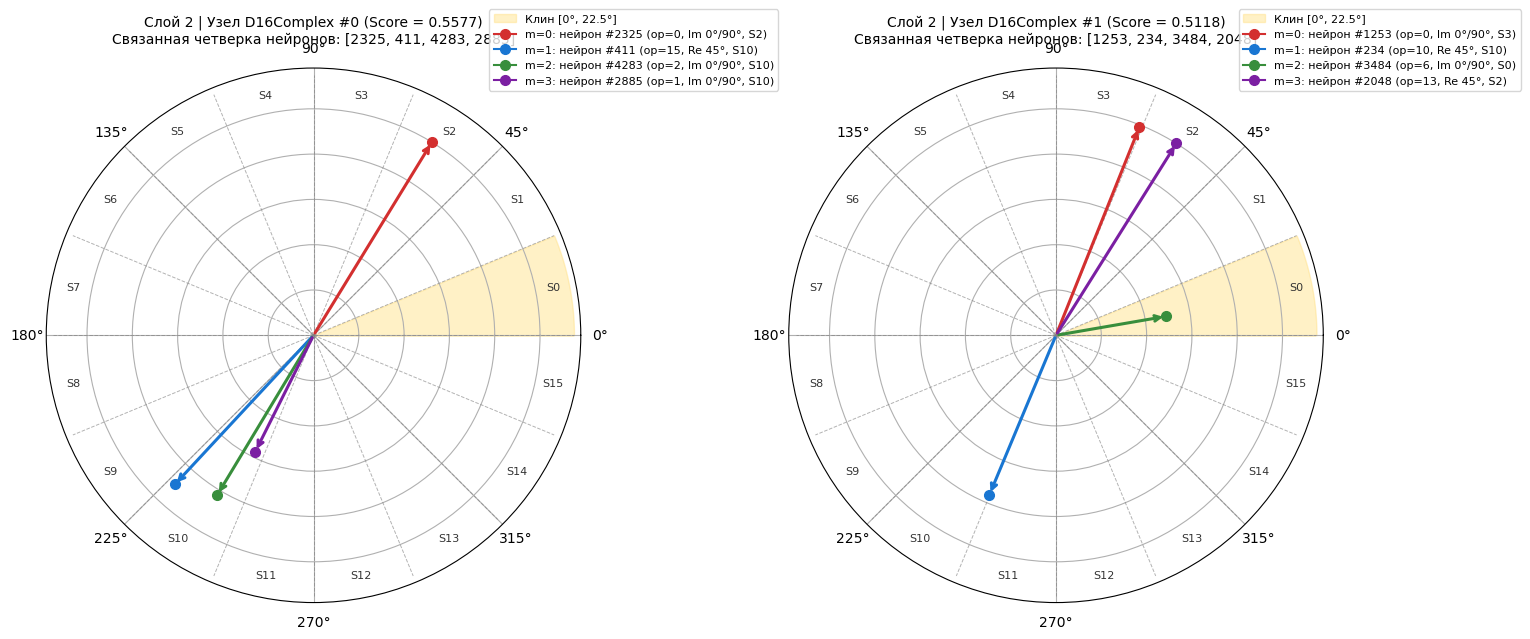

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), subplot_kw={"projection": "polar"})
plot_single_orbit_compass(layer_rep, unit_idx=0, ax=axes[0])
plot_single_orbit_compass(layer_rep, unit_idx=1, ax=axes[1])
plt.tight_layout()
plt.show()

## 4. Спектр 16 операций группы $\mathbb{Z}_8 \rtimes \mathbb{Z}_2$ и послойный профиль $45^\circ$-связей Адамара
Слева — распределение всех 16 операций в выбранном слое (синие столбцы `0..7` — осевая подгруппа $\mathrm{Im}(z^2)$, оранжевые столбцы `8..15` — $45^\circ$-повороты и отражения Адамара $\mathrm{Re}(z^2)$). Справа — динамика по всем слоям модели.

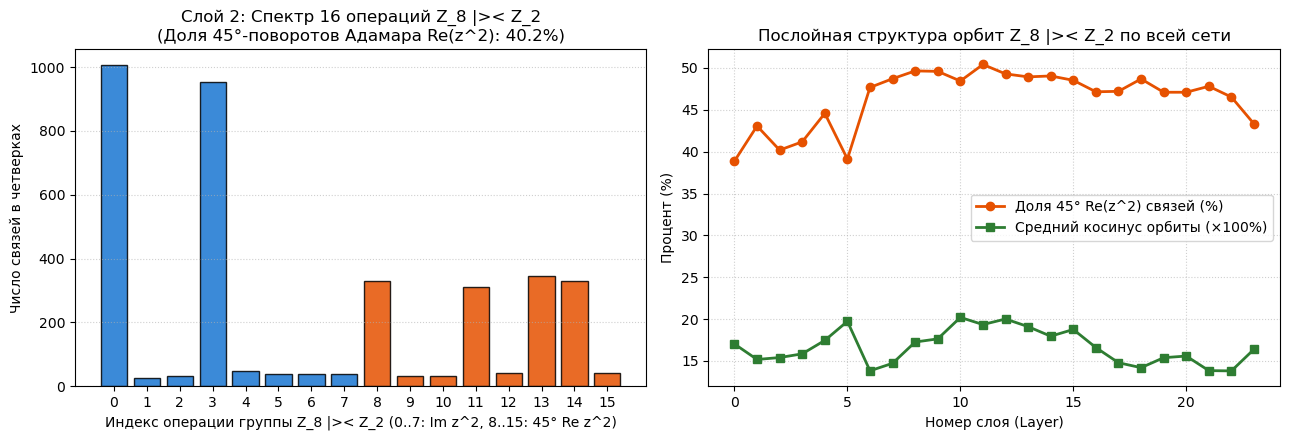

Глобальная гистограмма 16 операций Z_8 |>< Z_2 по всем слоям:
  0: (+L, +E) [Im, 0°]               :  17,129 ( 19.6%)
  1: (-L, -E) [Im, 180°]             :   1,208 (  1.4%)
  2: (+L, -E) [Im, conj]             :   1,213 (  1.4%)
  3: (-L, +E) [Im, -conj]            :  17,290 ( 19.7%)
  4: (-E, +L) [Im, +90°]             :   2,569 (  2.9%)
  5: (+E, -L) [Im, -90°]             :   2,529 (  2.9%)
  6: (+E, +L) [Im, swap]             :   2,499 (  2.9%)
  7: (-E, -L) [Im, -swap]            :   2,546 (  2.9%)
  8: (L-E, L+E)/√2 [Re, +45°]        :   8,364 (  9.6%)
  9: (-L-E, L-E)/√2 [Re, +135°]      :   1,691 (  1.9%)
  10: (-L+E, -L-E)/√2 [Re, +225°]    :   1,698 (  1.9%)
  11: (L+E, -L+E)/√2 [Re, +315°]     :   8,365 (  9.6%)
  12: (L+E, L-E)/√2 [Re, refl 22.5°] :   1,741 (  2.0%)
  13: (-L+E, L+E)/√2 [Re, refl 67.5°] :   8,392 (  9.6%)
  14: (-L-E, -L+E)/√2 [Re, refl 112.5°] :   8,605 (  9.8%)
  15: (L-E, -L-E)/√2 [Re, refl 157.5°] :   1,713 (  2.0%)


In [5]:
fig_spec = plot_layer_z8z2_spectrum(conv_report, layer_idx=INSPECT_LAYER)
plt.show()

print("Глобальная гистограмма 16 операций Z_8 |>< Z_2 по всем слоям:")
glob_hist = conv_report.global_op_histogram
tot_links = max(int(glob_hist.sum().item()), 1)
for op_id in range(16):
    cnt = int(glob_hist[op_id].item())
    print(f"  {OP_NAMES[op_id]:<34} : {cnt:7,d} ({cnt / tot_links * 100:5.1f}%)")

## 5. Полярные диаграммы 16-секторных коэффициентов `sector_im_gain` и `sector_re_gain`
Посмотрим, какие профили пропускания по 16 секторам аналитически скомпилировались для комплексных узлов в `D16QwenMLP`.

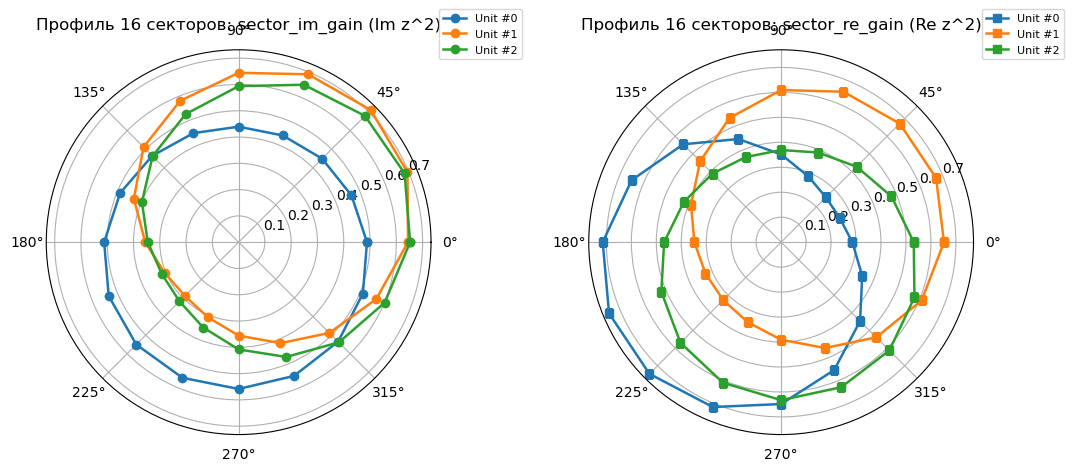

In [6]:
d16_mlp_layer = d16_model.model.layers[INSPECT_LAYER].mlp
fig_gains = plot_learned_sector_gains(d16_mlp_layer, unit_indices=(0, 1, 2))
plt.show()

## 6. Прогон сконвертированной модели и снятие 18-состояний `D16ComplexTensor`

In [7]:
d16_model.eval()
d16_model.set_collect_d16_stats(True, reset=True)

sample_ids = torch.randint(0, d16_model.config.vocab_size, (2, 32))
with torch.no_grad():
    out = d16_model(sample_ids)

summary = d16_model.get_d16_state_summary()
counts = summary["state_counts"]
tot = max(summary["total_elements"], 1)

print(f"Выход логитов: {tuple(out.logits.shape)} | Все значения конечны: {bool(torch.isfinite(out.logits).all())}")
print("=" * 72)
print("РАСПРЕДЕЛЕНИЕ АКТИВАЦИЙ СКОНВЕРТИРОВАННОЙ СЕТИ ПО 18 СОСТОЯНИЯМ D16Complex")
print("=" * 72)
for s_idx in range(18):
    c = int(counts[s_idx].item())
    print(f"  {s_idx:2d}: {STATE_LABELS[s_idx]:<14} | {c:9,d} | {c / tot * 100:6.2f}%")

Выход логитов: (2, 32, 151936) | Все значения конечны: True
РАСПРЕДЕЛЕНИЕ АКТИВАЦИЙ СКОНВЕРТИРОВАННОЙ СЕТИ ПО 18 СОСТОЯНИЯМ D16Complex
   0: Sector_0       |    60,111 |   3.22%
   1: Sector_1       |    52,010 |   2.78%
   2: Sector_2       |    51,975 |   2.78%
   3: Sector_3       |    60,290 |   3.23%
   4: Sector_4       |    62,216 |   3.33%
   5: Sector_5       |    52,613 |   2.82%
   6: Sector_6       |    51,987 |   2.78%
   7: Sector_7       |    60,730 |   3.25%
   8: Sector_8       |    79,705 |   4.27%
   9: Sector_9       |   122,290 |   6.55%
  10: Sector_10      |   200,131 |  10.71%
  11: Sector_11      |   304,761 |  16.32%
  12: Sector_12      |   304,087 |  16.28%
  13: Sector_13      |   197,868 |  10.59%
  14: Sector_14      |   124,028 |   6.64%
  15: Sector_15      |    82,974 |   4.44%
  16: Indifferent    |         0 |   0.00%
  17: Undefined      |         0 |   0.00%


## 7. Проверка Perplexity (PPL) и генерации текста на сконвертированном `Qwen2.5-0.5B`
Загрузим родной токенизатор из той же локальной папки `snap_dir`, замерим `NLL / Perplexity` на контрольном наборе текстов и проверим авторегрессионную генерацию `d16_model.generate(...)` сначала для уже сконвертированной в памяти модели `orbit_4to1` (`4864 -> 1216` узлов `D16Complex`), а затем сравним с беспотерьным подъёмом `full_1to1` (`4864 -> 4864` узлов `D16Complex` без единого вызова `sigmoid`).

In [8]:
import math
from transformers import AutoTokenizer

assert snap_dir is not None, "Для теста на реальном Qwen2.5-0.5B нужен локальный snap_dir"
qwen_tokenizer = AutoTokenizer.from_pretrained(str(snap_dir), local_files_only=True)

EVAL_TEXTS = [
    "The theory of general relativity describes gravitation as a geometric property of space and time.",
    "Complex numbers extend the real numbers by introducing the imaginary unit i, satisfying i^2 = -1.",
    "In deep neural networks, attention mechanisms route information across token positions.",
    "Water freezes at zero degrees Celsius and boils at one hundred degrees Celsius under standard pressure.",
]

GEN_PROMPTS = [
    "The capital of France is",
    "In mathematics, a complex number is",
    "Water boils at a temperature of",
    "Artificial intelligence can help scientists by",
]


@torch.no_grad()
def evaluate_d16_perplexity(model: D16QwenForCausalLM, tokenizer, texts, run_device) -> tuple[float, float]:
    model.eval()
    total_nll = 0.0
    total_tokens = 0

    for text in texts:
        enc = tokenizer(text, return_tensors="pt")
        input_ids = enc["input_ids"].to(run_device)
        if input_ids.shape[1] < 2:
            continue
        out = model(input_ids=input_ids, labels=input_ids)
        num_t = input_ids.shape[1] - 1
        total_nll += float(out.loss.item()) * num_t
        total_tokens += num_t

    mean_nll = total_nll / max(total_tokens, 1)
    ppl = math.exp(min(mean_nll, 20.0))
    return mean_nll, ppl


@torch.no_grad()
def run_d16_generation_test(model: D16QwenForCausalLM, tokenizer, prompts, run_device, max_new_tokens: int = 20):
    model.eval()
    for prompt in prompts:
        inp = tokenizer(prompt, return_tensors="pt")["input_ids"].to(run_device)
        out_ids = model.generate(
            inp,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            eos_token_id=tokenizer.eos_token_id,
            use_cache=True,
        )
        text_out = tokenizer.decode(out_ids[0].tolist(), skip_special_tokens=True)
        print(f"  Промпт : {prompt}")
        print(f"  Ответ  : {text_out}")
        print("-" * 92)


# Переносим уже созданную d16_model (orbit_4to1) на GPU для быстрого прогона
d16_model = d16_model.to(device)
nll_4to1, ppl_4to1 = evaluate_d16_perplexity(d16_model, qwen_tokenizer, EVAL_TEXTS, device)

print("=" * 92)
print(f"РЕЖИМ: {conv_report.mode} ({conv_report.orig_intermediate_size} -> {conv_report.d16_intermediate_size} D16Complex)")
print(f"Mean NLL: {nll_4to1:.4f} | Perplexity: {ppl_4to1:.2f}")
print("=" * 92)
run_d16_generation_test(d16_model, qwen_tokenizer, GEN_PROMPTS, device, max_new_tokens=20)

d:\conda\envs\torch_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


РЕЖИМ: orbit_4to1 (4864 -> 1216 D16Complex)
Mean NLL: 16.3139 | Perplexity: 12162360.50
  Промпт : The capital of France is
  Ответ  : The capital of France isamicamicamicamicamicamicamicamicamicamic乎乎乎乎乎乎乎乎乎乎
--------------------------------------------------------------------------------------------
  Промпт : In mathematics, a complex number is
  Ответ  : In mathematics, a complex number isimitimitimitimitimitimitimitimitimitimitimitimitimitimitimitimitimitimitimitimit
--------------------------------------------------------------------------------------------
  Промпт : Water boils at a temperature of
  Ответ  : Water boils at a temperature ofzazaza**********************************
--------------------------------------------------------------------------------------------
  Промпт : Artificial intelligence can help scientists by
  Ответ  : Artificial intelligence can help scientists by六六六六六六六六 �六 � � � �六 � � � � �
-----------------------------------------------------------------

In [9]:
# Освобождаем память GPU перед загрузкой второй конфигурации
d16_model = d16_model.to("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Конвертируем Qwen2.5-0.5B в режим full_1to1 (18-секторные таблицы без sigmoid)...")
d16_model_1to1, rep_1to1 = QwenToD16Converter.from_pretrained_dir(
    snap_dir, mode="full_1to1", device="cpu"
)
d16_model_1to1 = d16_model_1to1.to(device)

nll_1to1, ppl_1to1 = evaluate_d16_perplexity(d16_model_1to1, qwen_tokenizer, EVAL_TEXTS, device)

print("=" * 92)
print(f"РЕЖИМ: {rep_1to1.mode} ({rep_1to1.orig_intermediate_size} -> {rep_1to1.d16_intermediate_size} D16Complex)")
print(f"Mean NLL: {nll_1to1:.4f} | Perplexity: {ppl_1to1:.2f}")
print("=" * 92)
run_d16_generation_test(d16_model_1to1, qwen_tokenizer, GEN_PROMPTS, device, max_new_tokens=20)

Конвертируем Qwen2.5-0.5B в режим full_1to1 (18-секторные таблицы без sigmoid)...
РЕЖИМ: full_1to1 (4864 -> 4864 D16Complex)
Mean NLL: 3.4603 | Perplexity: 31.83
  Промпт : The capital of France is
  Ответ  : The capital of France is a large city in the French region of Haït, in the south of the French region of
--------------------------------------------------------------------------------------------
  Промпт : In mathematics, a complex number is
  Ответ  : In mathematics, a complex number is a number of the form a + b i c, where a and b are real numbers. The
--------------------------------------------------------------------------------------------
  Промпт : Water boils at a temperature of
  Ответ  : Water boils at a temperature of 100 degrees Celsius. What is the temperature of the water in the pot if the water
--------------------------------------------------------------------------------------------
  Промпт : Artificial intelligence can help scientists by
  Ответ  : Artifici